# M4: a harder null for the floor map

**Martin, with Claude, 16 November 2026; rerun 20 November on the G14 mentions (8,566 R–D mentions) with the phrase yield rule (G1c). Section 4 gives both runs.**

**Question.** The floor map is more divided by party than a map with the same degrees rewired at random
(prototype, section 4). But floor debate is organised: each debate has its own cast, often a manager from
each party. Is the floor map still more divided than chance **once we keep who was named in which debate**?

**The null.** Inside each debate, shuffle which mention points at which named member. Nothing moves between
debates.

It reads `mentions.parquet` (this folder) and `../data/processed/members.csv`, and writes
`figures/m4_debate_null.png`.

## 0. Every choice in one place

Confirmed by Martin on 16 November, before the null was run.

| # | Choice | Value here | Alternative and what it would change |
|---|---|---|---|
| 1 | What a debate is | One Congressional Record item (`doc_id`), usually one bill or motion | All items of one day: about 39 unrelated items mixed together, a null nearly as easy as plain rewiring |
| 2 | What is shuffled | Inside a debate, the named ends of the mentions. Each speaker keeps the number of mentions made in that debate; each named member keeps the number received in that debate | Redraw targets from the members who spoke in the debate: loses the 30% of mentions that name an absent member, the most cross-party ones |
| 3 | How | Swap the named members of two random mentions of the same debate; reject a swap that makes a member name themselves. 5 swaps per mention, 200 rewirings, seed 2805 | Fewer swaps would leave the null close to the data. The numbers are the prototype's (choices 13, 14) |
| 4 | Mentions that cannot move | Mentions in a debate with only one named member stay in the map, fixed. Their share is reported | Dropping them would change the observed map too. Keeping them makes the null harder to beat |
| 5 | What is measured | Party modularity and cross-party share of the undirected, unweighted map (as in the prototype), and the cross-party share counted per mention. The prototype's degree-preserving null is shown beside it | Per mention is the direct statistic for this null; per tie keeps the comparison with the prototype |
| 6 | Yields | Run twice: all mentions, and yields dropped. **Since 18 Nov `is_yield` is the phrase rule (G1c), and the headline drops yields (G1b)**; on 16 Nov it was the 60-character window | The window flag had 87% recall and 90% precision (D1) |
| 7 | Nodes | The 450 Republicans and Democrats. Mentions by or of the independent are left out | He has no party side |

**The reading, agreed before the run.** If the floor map is about as divided as this null, its party
division comes from who takes part in each debate, not from whom members choose to name. If it is clearly
more divided, members name their own side beyond what the debate structure forces. This null has no
counterpart for the working map, so it tests the floor map on its own.

In [1]:
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt

SEED = 2805
SWAPS_PER_MENTION = 5      # choice 3
SWAPS_PER_TIE = 5          # the prototype's degree-preserving null
N_REWIRE = 200

members = pd.read_csv("../data/processed/members.csv")
members = members[members.party.isin(["R", "D"])].reset_index(drop=True)            # choice 7
code_of = {b: i for i, b in enumerate(members.bioguide)}
is_R = (members.party == "R").values

M = pd.read_parquet("mentions.parquet")
M = M[M.speaker.isin(code_of) & M.named.isin(code_of)].reset_index(drop=True)
M["s"], M["n"] = M.speaker.map(code_of), M.named.map(code_of)
print(f"{len(M):,} mentions between Republicans and Democrats in {M.doc_id.nunique():,} debates")

8,566 mentions between Republicans and Democrats in 1,460 debates


## 1. The three numbers

`measure` takes the speaker and the named member of every mention and returns party modularity Q and the
cross-party share of the map (one undirected tie per pair), and the cross-party share per mention. Q for
two fixed groups is computed by hand and checked once against networkx.

In [2]:
def ties(s, n):
    """One undirected tie per pair of members."""
    return np.unique(np.stack([np.minimum(s, n), np.maximum(s, n)], axis=1), axis=0)

def tie_stats(e):
    """Party modularity Q and cross-party share of a list of ties."""
    a, b = is_R[e[:, 0]], is_R[e[:, 1]]
    m = len(e)
    q = sum((np.sum((a == g) & (b == g)) / m) - ((np.sum(a == g) + np.sum(b == g)) / (2 * m)) ** 2 for g in (True, False))
    return q, np.mean(a != b)

def measure(s, n):
    q, cross = tie_stats(ties(s, n))
    return q, cross, np.mean(is_R[s] != is_R[n])

# check Q against networkx on the observed map
e = ties(M.s.values, M.n.values)
G = nx.Graph(); G.add_nodes_from(range(len(members))); G.add_edges_from(map(tuple, e))
sides = [set(np.flatnonzero(is_R)), set(np.flatnonzero(~is_R))]
assert abs(tie_stats(e)[0] - nx.community.modularity(G, sides)) < 1e-12
print("observed (party Q, cross-party share of ties, cross-party share of mentions):", np.round(measure(M.s.values, M.n.values), 3))

observed (party Q, cross-party share of ties, cross-party share of mentions): [0.148 0.351 0.368]


## 2. The two nulls

In [3]:
def debate_null(D, n_rewire, rng):
    """Choices 2 and 3: shuffle the named ends inside each debate. Returns the three numbers per rewiring
    and the share of mentions that ended up pointing at a different member."""
    s, n0 = D.s.values, D.n.values
    groups = [g for g in D.groupby("doc_id").indices.values() if len(set(n0[g])) > 1]     # choice 4
    out, moved = [], []
    for _ in range(n_rewire):
        n = n0.copy()
        for g in groups:
            for i, j in g[rng.integers(len(g), size=(SWAPS_PER_MENTION * len(g), 2))]:
                if n[i] != n[j] and n[j] != s[i] and n[i] != s[j]:       # no self-mention
                    n[i], n[j] = n[j], n[i]
        out.append(measure(s, n)); moved.append(np.mean(n != n0))
    movable = sum(len(g) for g in groups) / len(D)
    return np.array(out), movable, float(np.mean(moved))

def degree_null(D, n_rewire):
    """The prototype's null: every member keeps their number of ties, the ties are rewired at random."""
    G = nx.Graph(); G.add_edges_from(map(tuple, ties(D.s.values, D.n.values)))
    m, out = G.number_of_edges(), []
    for k in range(n_rewire):
        R = G.copy()
        nx.double_edge_swap(R, nswap=SWAPS_PER_TIE * m, max_tries=200 * SWAPS_PER_TIE * m, seed=SEED + k)
        out.append(tie_stats(np.array(R.edges())))
    return np.array(out)

VARIANTS = {"All mentions": M, "Yields dropped": M[~M.is_yield]}       # choice 6
OBS, DEB, DEG, rows = {}, {}, {}, []
for name, D in VARIANTS.items():
    obs = measure(D.s.values, D.n.values)
    deb, movable, moved = debate_null(D, N_REWIRE, np.random.default_rng(SEED))
    deg = degree_null(D, N_REWIRE)
    OBS[name], DEB[name], DEG[name] = obs, deb, deg
    print(f"{name}: {len(D):,} mentions, {len(ties(D.s.values, D.n.values)):,} ties; "
          f"{movable:.0%} of mentions are in a debate with more than one named member; "
          f"{moved:.0%} point at a different member after shuffling")
    for label, k, null in [("party Q", 0, deg), ("cross-party share of ties", 1, deg),
                           ("party Q", 0, deb), ("cross-party share of ties", 1, deb), ("cross-party share of mentions", 2, deb)]:
        v = null[:, k]
        rows.append({"mentions": name, "null": "degree" if null is deg else "debate", "measure": label, "observed": obs[k],
                     "null mean": v.mean(), "null sd": v.std(), "null min": v.min(), "null max": v.max(),
                     "z": (obs[k] - v.mean()) / v.std(),
                     "rewirings at least as divided": int(np.sum(v >= obs[k]) if k == 0 else np.sum(v <= obs[k]))})
T = pd.DataFrame(rows).set_index(["mentions", "null", "measure"])
T.round(3)

All mentions: 8,566 mentions, 4,058 ties; 90% of mentions are in a debate with more than one named member; 54% point at a different member after shuffling


Yields dropped: 7,138 mentions, 3,573 ties; 86% of mentions are in a debate with more than one named member; 48% point at a different member after shuffling


observed  null mean  \
mentions       null   measure                                              
All mentions   degree party Q                           0.148     -0.002   
                      cross-party share of ties         0.351      0.502   
               debate party Q                           0.148      0.075   
                      cross-party share of ties         0.351      0.424   
                      cross-party share of mentions     0.368      0.443   
Yields dropped degree party Q                           0.106     -0.002   
                      cross-party share of ties         0.392      0.500   
               debate party Q                           0.106      0.070   
                      cross-party share of ties         0.392      0.428   
                      cross-party share of mentions     0.428      0.459   

                                                     null sd  null min  \
mentions       null   measure                                            
All mentions   degree party Q                          0.007    -0.022   
                      cross-party share of ties        0.007     0.483   
               debate party Q                          0.003     0.065   
                      cross-party share of ties        0.003     0.415   
                      cross-party share of mentions    0.003     0.434   
Yields dropped degree party Q                          0.008    -0.018   
                      cross-party share of ties        0.008     0.476   
               debate party Q                          0.004     0.059   
                      cross-party share of ties        0.004     0.418   
                      cross-party share of mentions    0.004     0.449   

                                                     null max       z  \
mentions       null   measure                                           
All mentions   degree party Q                           0.016  20.784   
                      cross-party share of ties         0.521 -20.784   
               debate party Q                           0.084  21.906   
                      cross-party share of ties         0.434 -21.862   
                      cross-party share of mentions     0.452 -22.613   
Yields dropped degree party Q                           0.022  13.873   
                      cross-party share of ties         0.517 -13.873   
               debate party Q                           0.079   9.528   
                      cross-party share of ties         0.439  -9.395   
                      cross-party share of mentions     0.469  -8.359   

                                                     rewirings at least as divided  
mentions       null   measure                                                       
All mentions   degree party Q                                                    0  
                      cross-party share of ties                                  0  
               debate party Q                                                    0  
                      cross-party share of ties                                  0  
                      cross-party share of mentions                              0  
Yields dropped degree party Q                                                    0  
                      cross-party share of ties                                  0  
               debate party Q                                                    0  
                      cross-party share of ties                                  0  
                      cross-party share of mentions                              0

## 3. The figure

Each panel: the observed value (black line), the debate null (blue) and, where it exists, the prototype's
degree-preserving null (grey). Top row all mentions, bottom row yields dropped.

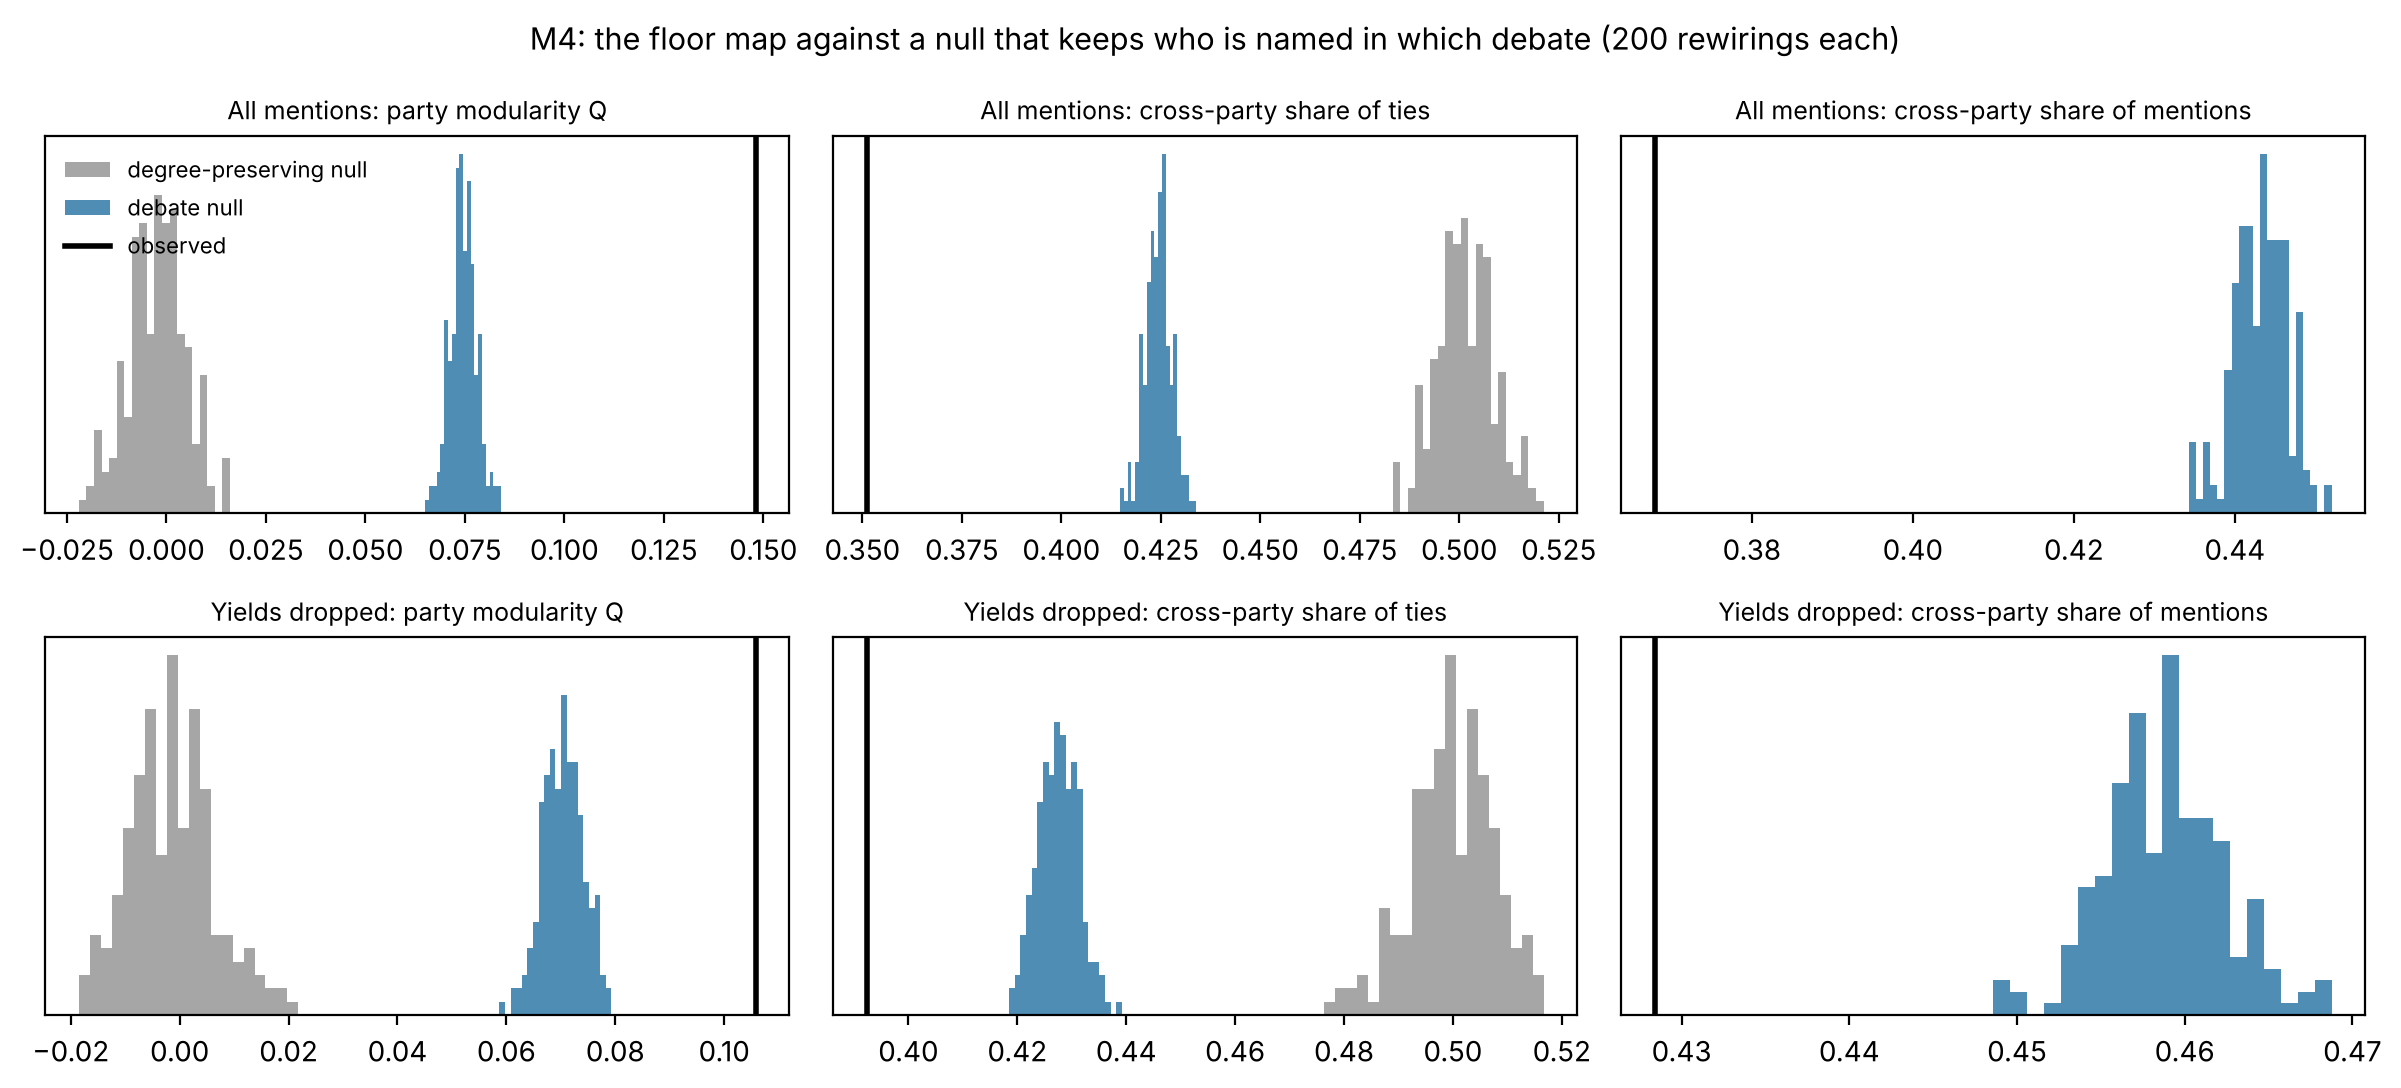

In [4]:
import os
os.makedirs("figures", exist_ok=True)
PANELS = [("party modularity Q", 0), ("cross-party share of ties", 1), ("cross-party share of mentions", 2)]
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5))
for r, name in enumerate(VARIANTS):
    for c, (label, k) in enumerate(PANELS):
        ax = axes[r, c]
        if k < 2: ax.hist(DEG[name][:, k], bins=20, color="grey", alpha=0.7, label="degree-preserving null")
        ax.hist(DEB[name][:, k], bins=20, color="#2471a3", alpha=0.8, label="debate null")
        ax.axvline(OBS[name][k], color="black", lw=2, label="observed")
        ax.set_title(f"{name}: {label}", fontsize=9); ax.set_yticks([])
        if r == 0 and c == 0: ax.legend(fontsize=8, frameon=False)
fig.suptitle("M4: the floor map against a null that keeps who is named in which debate (200 rewirings each)", fontsize=11)
fig.tight_layout(); fig.savefig("figures/m4_debate_null.png", dpi=150); plt.show()

## 4. What this run shows, and what it does not

**Rerun 20 November 2026** on the G14 mentions, phrase yield rule. **The headline is the second block** (G1b).

| Mentions | Measure | Observed | Degree-preserving null | Debate null (smallest to largest) |
|---|---|---|---|---|
| All (8,566) | Party modularity Q | 0.148 | -0.002 | 0.075 (0.065 to 0.084) |
| | Cross-party share of ties | 35.1% | 50.2% | 42.4% (41.5% to 43.4%) |
| | Cross-party share of mentions | 36.8% | | 44.3% (43.4% to 45.2%) |
| **Yields dropped (7,138), headline** | Party modularity Q | **0.106** | -0.002 | **0.070 (0.059 to 0.079)** |
| | Cross-party share of ties | 39.2% | 50.0% | 42.8% (41.8% to 43.9%) |
| | Cross-party share of mentions | 42.8% | | 45.9% (44.9% to 46.9%) |

On the headline map the debate structure explains about **two thirds** of the party division (0.070 of 0.106);
the map is still more divided than all 200 debate rewirings on all three measures, in both blocks. The
bullets below were written for the 16 Nov run; their reading still holds, with "about half" now "about two thirds"
for the headline map.

**First run, 16 November 2026** (first matcher, window yield rule):

| Mentions | Measure | Observed | Degree-preserving null | Debate null (smallest to largest) |
|---|---|---|---|---|
| All (8,041) | Party modularity Q | 0.156 | -0.003 | 0.077 (0.061 to 0.090) |
| | Cross-party share of ties | 34.2% | 50.1% | 42.2% (40.9% to 43.8%) |
| | Cross-party share of mentions | 36.0% | | 43.8% (42.8% to 44.9%) |
| Yields dropped (6,635) | Party modularity Q | 0.116 | -0.001 | 0.068 (0.058 to 0.083) |
| | Cross-party share of ties | 38.2% | 49.9% | 42.9% (41.4% to 43.9%) |
| | Cross-party share of mentions | 41.5% | | 45.5% (44.7% to 46.4%) |

- **The debate structure explains about half of the floor map's party division.** Shuffling names inside
  debates still leaves Q at 0.077, against about zero for plain rewiring. Who is named in which debate is
  already sorted by party.
- **The other half is not explained by it.** The observed map is more divided than every one of the 200
  debate rewirings, on all three measures, with and without yields. By the reading agreed in advance:
  members name their own side beyond what the debate structure forces.
- **Yields carry part of that.** Dropping them cuts the distance between the observed Q and the debate null
  from 0.079 to 0.048.

**What the null captures and misses**

- It keeps, for every debate, how many mentions each speaker made and how many each member received. It
  removes only the choice of *whom* a speaker names among the members named in that debate.
- It is a conservative null. 12% of mentions (15% without yields) sit in a debate with one named member and
  cannot move, and after shuffling only about half of all mentions point at a different member. A null that
  moves little is hard to beat, and the map beats it anyway.
- It says nothing about tone. A member naming their own side more than the debate forces may be thanking
  allies or yielding to them. Part 2 (the hand labels) decides that.
- It does not test the gap between the floor map and the working map. The working map has no debates.

**Not checked**

- Whether a Record item is the right unit. A long debate split over several items is treated as several.
- The mentions come from the first version of the shared matcher, whose precision has not been re-measured.
- A shuffle can merge two mentions into one tie, so a rewired map has a different number of ties from the
  observed one. Q and the shares are proportions, but they are not at exactly the same density.